17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Dataset downloaded successfully!
Training samples: 25000
Testing samples: 25000

After Padding:
Training shape: (25000, 200)
Testing shape: (25000, 200)

Sample Labels: [1 0 0 1 0 0 1 0 1 0]

Training RNN Model


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

... (12 outputs left out)

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 66s 202ms/step - accuracy: 0.5068 - loss: 0.6931 - val_accuracy: 0.5256 - val_loss: 0.6908
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 61s 194ms/step - accuracy: 0.5735 - loss: 0.6749 - val_accuracy: 0.5316 - val_loss: 0.6878
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 61s 196ms/step - accuracy: 0.7085 - loss: 0.5525 - val_accuracy: 0.7838 - val_loss: 0.4681
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 84s 202ms/step - accuracy: 0.8695 - loss: 0.3227 - val_accuracy: 0.8692 - val_loss: 0.3262
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 61s 194ms/step - accuracy: 0.9284 - loss: 0.2001 - val_accuracy: 0.8658 - val_loss: 0.3336

 GRU Evaluation:
Accuracy: 0.8558
Precision: 0.8386
Recall: 0.8812
F1 Score: 0.8594

Classification Report:
              precision    recall  f1-score   support

    Negative       0.87      0.83      0.85     12500
    Positive       0.84      0.88      0.86     12500

    accuracy                           0.86     25000
   macro avg       0.86

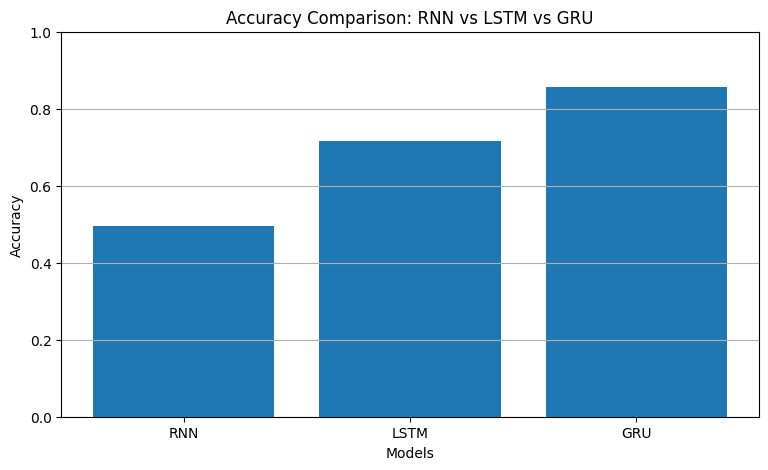

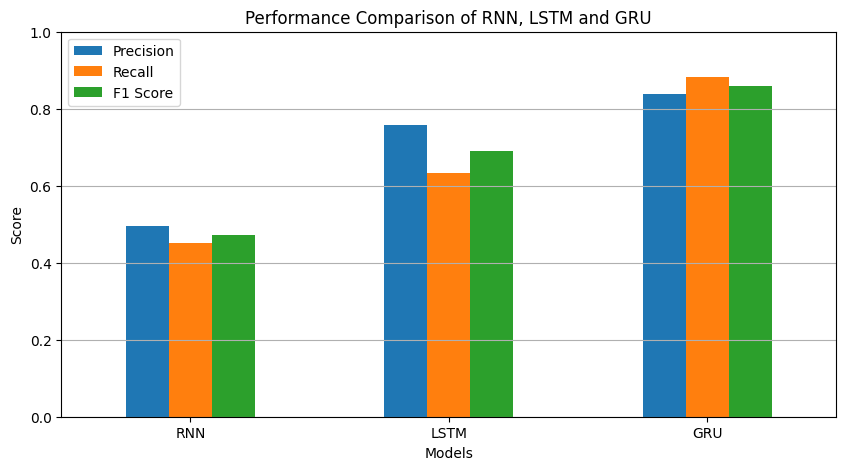

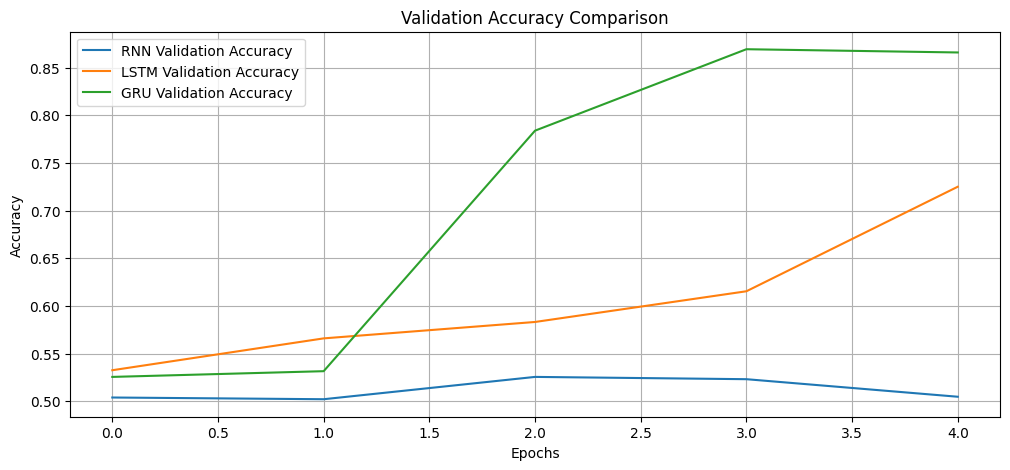

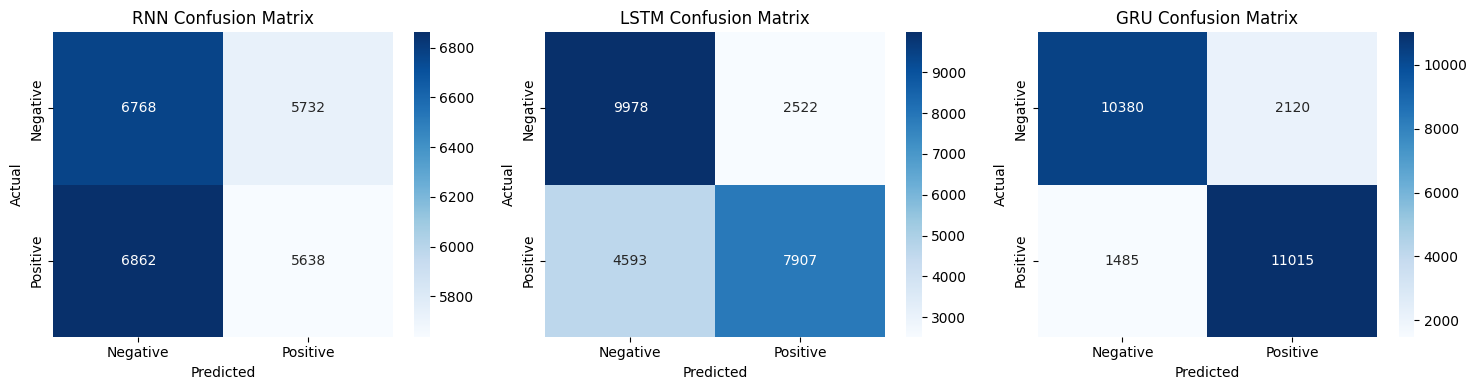


========== BEST MODEL ==========
Best Model: GRU
Accuracy: 0.8558
Precision: 0.8386
Recall: 0.8812
F1 Score: 0.8594

All models and results saved successfully!
1. rnn_model.keras
2. lstm_model.keras
3. gru_model.keras
4. model_comparison_results.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


PRACTICAL COMPLETED SUCCESSFULLY!


In [1]:

# ============================================================
# PRACTICAL: IMPLEMENT AND COMPARE RNN, LSTM AND GRU
# TASK: SEQUENCE CLASSIFICATION
# DATASET: IMDB MOVIE REVIEWS DATASET
# ============================================================

# 1. IMPORT REQUIRED LIBRARIES

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, GRU, Dense, Dropout

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import seaborn as sns

# Set random seed for reproducibility
np.random.seed(42)
tf.random.set_seed(42)


# 2. LOAD AND DOWNLOAD IMDB DATASET

# Limit vocabulary to the 10,000 most frequent words
vocab_size = 10000

print("Downloading IMDB dataset...")

(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

print("\nDataset downloaded successfully!")

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


# 3. DATA PREPROCESSING

# Set maximum review length
max_length = 200

# Make all sequences the same length
X_train = pad_sequences(
    X_train,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

X_test = pad_sequences(
    X_test,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

print("\nAfter Padding:")
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

# Display sample labels
print("\nSample Labels:", y_train[:10])


# 4. DEFINE MODEL CREATION FUNCTION

def create_model(model_type):

    model = Sequential()

    # Embedding layer converts words into dense vectors
    model.add(
        Embedding(
            input_dim=vocab_size,
            output_dim=64,
            input_length=max_length
        )
    )

    # Select the required sequence model
    if model_type == "RNN":

        model.add(SimpleRNN(64))

    elif model_type == "LSTM":

        model.add(LSTM(64))

    elif model_type == "GRU":

        model.add(GRU(64))

    # Dropout to reduce overfitting
    model.add(Dropout(0.5))

    # Output layer for binary classification
    model.add(Dense(1, activation='sigmoid'))

    # Compile the model
    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model


# 5. TRAIN AND COMPARE ALL THREE MODELS

models = {}
histories = {}
results = []

model_types = ["RNN", "LSTM", "GRU"]

for model_type in model_types:

    print("\n================================")
    print("Training", model_type, "Model")
    print("================================")

    # Create model
    model = create_model(model_type)

    # Display architecture
    model.summary()

    # Train model
    history = model.fit(
        X_train,
        y_train,
        epochs=5,
        batch_size=64,
        validation_split=0.2,
        verbose=1
    )

    # Save trained model and history
    models[model_type] = model
    histories[model_type] = history

    # Predict probabilities
    y_probability = model.predict(
        X_test,
        verbose=0
    )

    # Convert probabilities into binary classes
    y_pred = (y_probability >= 0.5).astype(int).flatten()

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    # Store model results
    results.append({
        "Model": model_type,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    print("\n", model_type, "Evaluation:")
    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1 Score:", round(f1, 4))

    print("\nClassification Report:")
    print(
        classification_report(
            y_test,
            y_pred,
            target_names=["Negative", "Positive"],
            zero_division=0
        )
    )


# 6. CREATE MODEL COMPARISON TABLE

comparison_df = pd.DataFrame(results)

print("\n========== MODEL COMPARISON ==========")

print(comparison_df.to_string(index=False))


# 7. VISUALIZE MODEL ACCURACY

plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Accuracy"]
)

plt.title("Accuracy Comparison: RNN vs LSTM vs GRU")
plt.xlabel("Models")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.grid(axis='y')

plt.show()


# 8. COMPARE PRECISION, RECALL AND F1 SCORE

comparison_df.set_index("Model")[
    ["Precision", "Recall", "F1 Score"]
].plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title("Performance Comparison of RNN, LSTM and GRU")
plt.xlabel("Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.legend()
plt.show()


# 9. PLOT TRAINING AND VALIDATION ACCURACY

plt.figure(figsize=(12, 5))

for model_type in model_types:

    plt.plot(
        histories[model_type].history['val_accuracy'],
        label=model_type + ' Validation Accuracy'
    )

plt.title("Validation Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


# 10. CONFUSION MATRICES FOR ALL MODELS

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, model_type in enumerate(model_types):

    # Generate predictions
    y_probability = models[model_type].predict(
        X_test,
        verbose=0
    )

    y_pred = (y_probability >= 0.5).astype(int).flatten()

    # Calculate confusion matrix
    cm = confusion_matrix(y_test, y_pred)

    # Display confusion matrix
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Negative', 'Positive'],
        yticklabels=['Negative', 'Positive'],
        ax=axes[i]
    )

    axes[i].set_title(model_type + " Confusion Matrix")
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

plt.tight_layout()
plt.show()


# 11. FIND BEST PERFORMING MODEL

best_model = comparison_df.loc[
    comparison_df["F1 Score"].idxmax()
]

print("\n========== BEST MODEL ==========")

print("Best Model:", best_model["Model"])
print("Accuracy:", round(best_model["Accuracy"], 4))
print("Precision:", round(best_model["Precision"], 4))
print("Recall:", round(best_model["Recall"], 4))
print("F1 Score:", round(best_model["F1 Score"], 4))


# 12. SAVE MODELS AND RESULTS

# Save all three trained models
for model_type in model_types:

    models[model_type].save(
        model_type.lower() + "_model.keras"
    )

# Save comparison results
comparison_df.to_csv(
    "model_comparison_results.csv",
    index=False
)

print("\nAll models and results saved successfully!")

print("1. rnn_model.keras")
print("2. lstm_model.keras")
print("3. gru_model.keras")
print("4. model_comparison_results.csv")


# 13. DOWNLOAD RESULT FILES

from google.colab import files

files.download("model_comparison_results.csv")

for model_type in model_types:

    files.download(
        model_type.lower() + "_model.keras"
    )

print("\nPRACTICAL COMPLETED SUCCESSFULLY!")
